# Week 7 · Day 2 — Analysing the offer-screen test: starter

Kamola wants a decision; Nilufar wants to know what it does to first-payment defaults. Load, read the naive result,
then **three functions** (TODO + assert) that make the analysis trustworthy. Practice tasks P1–P10 on the page: one cell each, below.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_effectsize, proportion_confint
from statsmodels.stats.power import NormalIndPower, zt_ind_solve_power
from statsmodels.stats.multitest import multipletests
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
DATA = Path("../..")           # this notebook lives in data/python/week7/, so "../.." is the data/ folder
AB = DATA / "ab"
rng = np.random.default_rng(2026)   # one seeded generator: the same "random" numbers on every run

In [2]:
# The experiment: new loan-offer screen, 2026-08-01 .. 2026-08-28 (data/ab/README.md). Run, do not edit.
users = pd.read_csv(AB / "users.csv", parse_dates=["assigned_at"])
events = pd.read_csv(AB / "events.csv", parse_dates=["event_time"])
loans = pd.read_csv(AB / "loans_followup.csv", parse_dates=["signed_at"])
assert (len(users), len(events), len(loans)) == (27974, 67215, 2583)
print(f"users {len(users)} rows · events {len(events)} · signed loans {len(loans)}")
print(users["variant"].value_counts().to_dict(), "·", users["assigned_at"].min(), "→", users["assigned_at"].max())

def with_conversion(u, ev, window_days=7):
    """One row per row of u, plus `signed` (first contract_signed time) and `conv` (1 if signed within the window)."""
    s = ev[ev["event_name"] == "contract_signed"].groupby("user_id")["event_time"].min().rename("signed")
    x = u.merge(s, on="user_id", how="left")
    x["conv"] = ((x["signed"] - x["assigned_at"]).dt.total_seconds() <= window_days * 86400).astype(int)
    return x

users 27974 rows · events 67215 · signed loans 2583
{'B': 14129, 'A': 13845} · 2026-08-01 00:02:57 → 2026-08-28 23:57:35


## 0. The naive result — every row, as exported (do not stop here)

In [3]:
x = with_conversion(users, events)
k = x.groupby("variant")["conv"].agg(converters="sum", users="size")
k["rate"] = k["converters"] / k["users"]
z, p = proportions_ztest(k["converters"][::-1], k["users"][::-1])
print(k, f"\nz = {z:.3f}, p = {p:.5f} — looks like a clear win. Before believing it: is the experiment itself sound?")

         converters  users      rate
variant                             
A              1147  13845  0.082846
B              1324  14129  0.093708 
z = 3.201, p = 0.00137 — looks like a clear win. Before believing it: is the experiment itself sound?


## 0b. Daily conversion by variant (users de-duplicated) — what do the first days look like?

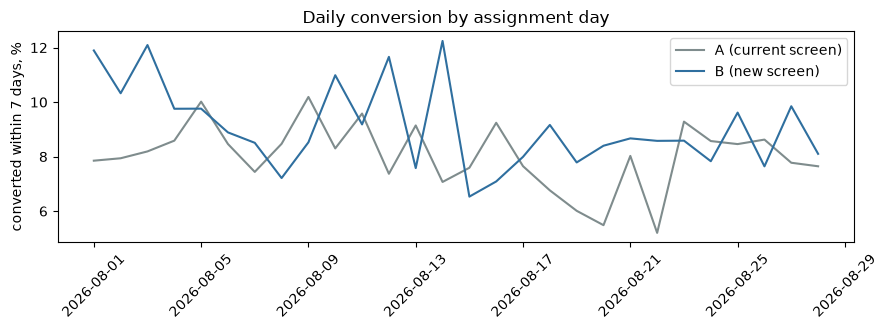

variant,A,B,lift
assigned_at,,,
2026-08-01,7.85,11.90,4.04
2026-08-02,7.94,10.33,2.39
2026-08-03,8.19,12.09,3.90
2026-08-04,8.59,9.76,1.17
2026-08-05,10.02,9.76,-0.26
2026-08-06,8.46,8.89,0.43
2026-08-07,7.44,8.51,1.07


In [4]:
xd = with_conversion(users.drop_duplicates("user_id", keep=False), events)
daily = xd.groupby([xd["assigned_at"].dt.date, "variant"])["conv"].mean().unstack() * 100
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(daily.index, daily["A"], label="A (current screen)", color="#7f8c8d")
ax.plot(daily.index, daily["B"], label="B (new screen)", color="#2f6f9f")
ax.set_ylabel("converted within 7 days, %"); ax.legend(); ax.set_title("Daily conversion by assignment day")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()
(daily.assign(lift=daily["B"] - daily["A"]).round(2)).head(7)

## 1. `srm_by(users, col)` — the split within each value of a column
Return a DataFrame indexed by the column's values with columns `A`, `B`, `share_b`, `p` (chi-square vs 50/50).
Use it on `device`, on the assignment week, on `device` × week. Remember: check sample ratios with a strict threshold
(p < 0.001) — you are about to run many of these checks.

In [5]:
def srm_by(u, col):
    """Split counts and SRM p-value per value of `col` (a column name, or a list of column names)."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [6]:
ud = users.drop_duplicates("user_id", keep=False).assign(week=lambda t: (t.assigned_at - pd.Timestamp("2026-08-01")).dt.days // 7 + 1)
s = srm_by(ud, "device")
assert s.loc["iOS", "p"] < 1e-4 and s.loc["Android", "p"] > 0.5
s2 = srm_by(ud, ["device", "week"])
assert s2.loc[("iOS", 4), "p"] < 1e-12
print(s, "\n", s2.round(4))

NotImplementedError: TODO: write me, then run the assert cell below

## 2. `clean_users(users)` — the analysis population
Drop every row of a user who appears more than once; drop iOS users assigned 2026-08-22 … 2026-08-28; keep users assigned
from 2026-08-04 (after the novelty days). Return the cleaned DataFrame (one row per user).

In [7]:
def clean_users(u):
    """The three cleaning rules, in that order; returns one row per user."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [8]:
c = clean_users(users)
assert c["user_id"].is_unique and len(c) == 22906
assert c["variant"].value_counts().to_dict() == {"A": 11472, "B": 11434}
print("clean_users OK —", len(c), "users")

NotImplementedError: TODO: write me, then run the assert cell below

## 3. `ab_readout(x)` — the primary result in one dict
From a frame with `variant` and `conv`: rates, difference B − A with its 95 % Newcombe CI, z-test p, relative lift
B / A − 1 with its 95 % CI (`confint_proportions_2indep(..., compare="ratio", method="log")`, minus 1).

In [9]:
def ab_readout(x):
    """dict: rate_a, rate_b, diff, ci_low, ci_high, p, rel, rel_low, rel_high."""
    raise NotImplementedError("TODO: write me, then run the assert cell below")

In [10]:
r = ab_readout(with_conversion(clean_users(users), events))
assert abs(r["p"] - 0.0160) < 5e-4 and abs(r["rel"] - 0.1108) < 5e-4
assert abs(r["ci_low"] - 0.00164) < 5e-5 and abs(r["rel_high"] - 0.2100) < 5e-4
print({k: round(v, 5) for k, v in r.items()})

NotImplementedError: TODO: write me, then run the assert cell below

## Practice — one cell per task (P1 … P10 on the page)

In [11]:
# P1